# Phase 3 — Deep Learning & Neural Networks
## Notebook 03: Neural Networks from Scratch (NumPy Bridge & Dual Verification)

### Executive Overview & Mathematical Rationale
Modern deep learning frameworks—PyTorch and TensorFlow/Keras—encapsulate automatic differentiation behind convenient abstractions like `.backward()` and `tf.GradientTape`. While these abstractions maximize productivity, treating them as opaque "black boxes" leads to critical blindspots: an inability to diagnose exploding or vanishing gradients, misunderstanding memory bandwidth vs. compute trade-offs, and difficulty debugging numerical instability.

This notebook serves as the **conceptual and mathematical bridge** connecting classical machine learning to modern deep learning. We implement an arbitrary-depth ($L$-layer) Multi-Layer Perceptron (MLP) from first principles using pure **NumPy** vectorization.

```
+-----------------------------------------------------------------------------------+
|               The Forward & Backward Computational Graph Architecture             |
+-----------------------------------------------------------------------------------+
| Forward:   X = A[0] ---> [ Z[1] = W[1]A[0] + b[1] ] ---> A[1] = g[1](Z[1]) ---> ...|
| Backward:  dX = dA[0] <-- [ dW[1], db[1], dZ[1] ]  <-- dA[1] <--- dZ[2] <--- ...|
+-----------------------------------------------------------------------------------+
                                        |
           +----------------------------+----------------------------+
           |                                                         |
           v                                                         v
   [PyTorch Autograd]                                      [TensorFlow Tape]
   torch.autograd.grad                                     tape.gradient
           |                                                         |
           +----------------------------+----------------------------+
                                        v
                    Dual Relative Error Tolerance: < 1e-7
```

### Dual Framework Verification Paradigm
To rigorously prove the mathematical correctness of our manual matrix calculus derivations, every analytical gradient computed by our scratch NumPy engine ($
abla_{W^{[l]}} \mathcal{L}$, $
abla_{b^{[l]}} \mathcal{L}$) is **simultaneously verified against both PyTorch Autograd and TensorFlow GradientTape** on identical numerical inputs, ensuring relative errors strictly below $10^{-7}$.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Derive Matrix Calculus Backpropagation**: Mathematically derive multivariate chain-rule equations for arbitrary linear layers and nonlinear activation functions.
2. **Implement Vectorized Forward/Backward Propagation**: Build an object-oriented $L$-layer neural network engine in pure NumPy supporting mini-batch vectorization.
3. **Execute Dual Framework Verification**: Validate analytical scratch gradients against both PyTorch Autograd and TensorFlow GradientTape to confirm machine-precision parity.
4. **Diagnose Gradient Dynamics**: Visualize and quantify gradient flow magnitude ($\|
abla_{W^{[l]}} \mathcal{L}\|_2$) across deep network architectures to identify vanishing/exploding gradients.
5. **Implement Production Optimizers & Normalization**: Code the Adam optimizer and Vectorized Batch Normalization entirely from scratch with analytical backward equations.


In [1]:
import sys
import os
import time
import platform
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import torch
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split

# Visual formatting
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

# Suppress TF logs
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

print(f"Python Platform:    {platform.python_implementation()} {platform.python_version()}")
print(f"NumPy Version:      {np.__version__}")
print(f"PyTorch Version:    {torch.__version__}")
print(f"TensorFlow Version: {tf.__version__}")


I0000 00:00:1794180011.694659     511 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794180011.734492     511 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794180013.072902     511 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python Platform:    CPython 3.11.2
NumPy Version:      2.4.6
PyTorch Version:    2.15.0+cpu
TensorFlow Version: 2.21.0


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    """Enforce deterministic random number generation across all three engines."""
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    tf.keras.utils.set_random_seed(seed)
    print(f"Global seed {seed} synchronized across NumPy, PyTorch, and TensorFlow.")

configure_reproducibility(42)


Global seed 42 synchronized across NumPy, PyTorch, and TensorFlow.


### Mathematical Derivation of Deep Backpropagation

Consider an $L$-layer neural network processing a mini-batch of $m$ input samples $X \in \mathbb{R}^{n_x \times m}$.

#### 1. Forward Propagation Mechanics
For each layer $l \in \{1, 2, \dots, L\}$:
$$Z^{[l]} = W^{[l]} A^{[l-1]} + b^{[l]}$$
$$A^{[l]} = g^{[l]}\left(Z^{[l]}\right)$$

Where:
- $W^{[l]} \in \mathbb{R}^{n_l \times n_{l-1}}$: Weight matrix for layer $l$.
- $b^{[l]} \in \mathbb{R}^{n_l \times 1}$: Bias vector for layer $l$ (broadcast across $m$ columns).
- $A^{[0]} = X \in \mathbb{R}^{n_0 \times m}$: Input data matrix.
- $g^{[l]}(\cdot)$: Elementwise activation function.

#### 2. Softmax Output & Categorical Cross-Entropy Derivation
For $K$ classes, the final layer $L$ computes the Softmax activation:
$$\hat{y}_k = A^{[L]}_k = \frac{e^{Z^{[L]}_k}}{\sum_{j=1}^K e^{Z^{[L]}_j}}$$

The Categorical Cross-Entropy loss over the mini-batch of $m$ samples is:
$$\mathcal{L} = -\frac{1}{m} \sum_{i=1}^m \sum_{k=1}^K Y_{ki} \ln A^{[L]}_{ki}$$

Applying the multivariate chain rule to compute $\frac{\partial \mathcal{L}}{\partial Z^{[L]}}$:
$$\frac{\partial \mathcal{L}}{\partial Z^{[L]}_i} = \sum_{k=1}^K \frac{\partial \mathcal{L}}{\partial A^{[L]}_k} \frac{\partial A^{[L]}_k}{\partial Z^{[L]}_i}$$

Since $\frac{\partial A^{[L]}_k}{\partial Z^{[L]}_i} = A^{[L]}_k (\delta_{ki} - A^{[L]}_i)$, substituting yields the remarkably elegant result:
$$\frac{\partial \mathcal{L}}{\partial Z^{[L]}} = \frac{1}{m} \left( A^{[L]} - Y \right) \triangleq dZ^{[L]}$$

#### 3. General Layer Backpropagation Equations
For any hidden layer $l \in \{L-1, L-2, \dots, 1\}$:
$$dA^{[l]} = \left(W^{[l+1]}\right)^T dZ^{[l+1]}$$
$$dZ^{[l]} = dA^{[l]} \odot {g^{[l]}}'\left(Z^{[l]}\right)$$
$$dW^{[l]} = dZ^{[l]} \left(A^{[l-1]}\right)^T$$
$$db^{[l]} = \sum_{\text{samples } i=1}^m dZ^{[l]}_{:, i} \quad \text{(summed across columns)}$$

#### 4. Weight Initialization
- **He (Kaiming) Initialization** (for ReLU/GELU activations):
  $$W^{[l]} \sim \mathcal{N}\left(0, \sqrt{\frac{2}{n_{l-1}}}\right)$$
- **Xavier (Glorot) Initialization** (for Tanh/Sigmoid activations):
  $$W^{[l]} \sim \mathcal{N}\left(0, \sqrt{\frac{1}{n_{l-1}}}\right)$$


### 1. Pure NumPy Activation Functions & Derivatives
We implement numerically stable activations and their analytical derivatives:
- **Sigmoid**: $\sigma(z) = rac{1}{1 + e^{-z}}$, with derivative $\sigma(z)(1 - \sigma(z))$.
- **ReLU**: $\max(0, z)$, with subgradient $\mathbb{I}(z > 0)$.
- **Tanh**: $rac{e^z - e^{-z}}{e^z + e^{-z}}$, with derivative $1 - 	anh^2(z)$.
- **Softmax**: Stable via subtractive max normalization: $rac{e^{z - \max(z)}}{\sum e^{z - \max(z)}}$.


In [3]:
class Activations:
    @staticmethod
    def relu(z: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Forward and backward ReLU activation."""
        a = np.maximum(0.0, z)
        cache = z
        return a, cache

    @staticmethod
    def relu_backward(da: np.ndarray, cache: np.ndarray) -> np.ndarray:
        z = cache
        dz = np.array(da, copy=True)
        dz[z <= 0] = 0.0
        return dz

    @staticmethod
    def sigmoid(z: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Numerically stable sigmoid."""
        # Avoid overflow for large negative values
        a = np.where(z >= 0, 1.0 / (1.0 + np.exp(-z)), np.exp(z) / (1.0 + np.exp(z)))
        cache = a
        return a, cache

    @staticmethod
    def sigmoid_backward(da: np.ndarray, cache: np.ndarray) -> np.ndarray:
        a = cache
        dz = da * a * (1.0 - a)
        return dz

    @staticmethod
    def tanh(z: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
        """Hyperbolic tangent."""
        a = np.tanh(z)
        cache = a
        return a, cache

    @staticmethod
    def tanh_backward(da: np.ndarray, cache: np.ndarray) -> np.ndarray:
        a = cache
        dz = da * (1.0 - np.square(a))
        return dz

    @staticmethod
    def softmax(z: np.ndarray) -> np.ndarray:
        """Numerically stable softmax along axis 0 (features/classes)."""
        shifted_z = z - np.max(z, axis=0, keepdims=True)
        exp_z = np.exp(shifted_z)
        return exp_z / np.sum(exp_z, axis=0, keepdims=True)


### 2. Deep Multi-Layer Perceptron (MLP) Engine in Pure NumPy
Our `ModularMLP` class encapsulates:
1. Multi-layer weight and bias initialization with He or Xavier scaling.
2. Full forward propagation caching activations and linear pre-activations.
3. Full backward propagation calculating exact gradient matrices.
4. Parameter update via Gradient Descent.


In [4]:
class ModularMLP:
    """
    L-layer fully connected neural network engine implemented entirely in NumPy.
    Input shape: (n_features, n_samples)
    Output shape: (n_classes, n_samples)
    """
    def __init__(self, layer_dims: List[int], activation: str = "relu"):
        self.layer_dims = layer_dims
        self.num_layers = len(layer_dims) - 1
        self.activation = activation.lower()
        self.parameters: Dict[str, np.ndarray] = {}
        self._initialize_parameters()

    def _initialize_parameters(self) -> None:
        """Initializes weights with He or Xavier scaling."""
        for l in range(1, self.num_layers + 1):
            n_in = self.layer_dims[l - 1]
            n_out = self.layer_dims[l]
            if self.activation == "relu":
                scale = np.sqrt(2.0 / n_in)  # He initialization
            else:
                scale = np.sqrt(1.0 / n_in)  # Xavier initialization
            
            self.parameters[f"W{l}"] = np.random.randn(n_out, n_in) * scale
            self.parameters[f"b{l}"] = np.zeros((n_out, 1), dtype=np.float64)

    def forward(self, X: np.ndarray) -> Tuple[np.ndarray, Dict[str, Any]]:
        """
        Executes full forward pass through L layers.
        Returns: (A_final, caches_dict)
        """
        caches = {}
        A = X
        caches["A0"] = A

        for l in range(1, self.num_layers):
            W = self.parameters[f"W{l}"]
            b = self.parameters[f"b{l}"]
            Z = np.dot(W, A) + b
            caches[f"Z{l}"] = Z

            if self.activation == "relu":
                A, act_cache = Activations.relu(Z)
            elif self.activation == "tanh":
                A, act_cache = Activations.tanh(Z)
            else:
                A, act_cache = Activations.sigmoid(Z)

            caches[f"A{l}"] = A
            caches[f"act_cache{l}"] = act_cache

        # Output Layer: Softmax
        W_last = self.parameters[f"W{self.num_layers}"]
        b_last = self.parameters[f"b{self.num_layers}"]
        Z_last = np.dot(W_last, A) + b_last
        caches[f"Z{self.num_layers}"] = Z_last
        A_last = Activations.softmax(Z_last)
        caches[f"A{self.num_layers}"] = A_last

        return A_last, caches

    def compute_loss(self, A_last: np.ndarray, Y: np.ndarray) -> float:
        """
        Categorical Cross-Entropy Loss: -1/m * sum(Y * log(A_last + eps))
        """
        m = Y.shape[1]
        eps = 1e-15
        clipped_A = np.clip(A_last, eps, 1.0 - eps)
        loss = -np.sum(Y * np.log(clipped_A)) / m
        return float(np.squeeze(loss))

    def backward(self, caches: Dict[str, Any], Y: np.ndarray) -> Dict[str, np.ndarray]:
        """
        Executes full analytical backward propagation.
        Returns: gradients dict containing dW1..dWL, db1..dbL
        """
        grads = {}
        m = Y.shape[1]
        L = self.num_layers

        # Gradient of Softmax + Cross-Entropy: dZ[L] = (A[L] - Y) / m
        A_last = caches[f"A{L}"]
        dZ = (A_last - Y) / m
        A_prev = caches[f"A{L-1}"]

        grads[f"dW{L}"] = np.dot(dZ, A_prev.T)
        grads[f"db{L}"] = np.sum(dZ, axis=1, keepdims=True)

        # Backprop through hidden layers
        for l in reversed(range(1, L)):
            W_next = self.parameters[f"W{l+1}"]
            dA = np.dot(W_next.T, dZ)
            
            act_cache = caches[f"act_cache{l}"]
            if self.activation == "relu":
                dZ = Activations.relu_backward(dA, act_cache)
            elif self.activation == "tanh":
                dZ = Activations.tanh_backward(dA, act_cache)
            else:
                dZ = Activations.sigmoid_backward(dA, act_cache)

            A_prev = caches[f"A{l-1}"]
            grads[f"dW{l}"] = np.dot(dZ, A_prev.T)
            grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True)

        return grads

    def update_parameters(self, grads: Dict[str, np.ndarray], learning_rate: float) -> None:
        """Performs vanilla gradient descent parameter update."""
        for l in range(1, self.num_layers + 1):
            self.parameters[f"W{l}"] -= learning_rate * grads[f"dW{l}"]
            self.parameters[f"b{l}"] -= learning_rate * grads[f"db{l}"]


### 3. Dual Framework Verification: NumPy vs. PyTorch vs. TensorFlow
We construct a test fixture with identical inputs $X$ and weights $W, b$. We compute the analytical gradients using our scratch engine, and compare them directly against:
1. **PyTorch**: Built with `torch.tensor(..., requires_grad=True)` and `torch.autograd.grad`.
2. **TensorFlow**: Built with `tf.Variable(...)` and `tf.GradientTape().gradient`.

We calculate the relative Frobenius error:
$$	ext{Relative Error} = rac{\|
abla_{	ext{scratch}} - 
abla_{	ext{framework}}\|_2}{\|
abla_{	ext{scratch}}\|_2 + \|
abla_{	ext{framework}}\|_2 + 10^{-15}}$$


In [5]:
def verify_scratch_gradients_dual(layer_dims: List[int] = [4, 6, 3], num_samples: int = 8) -> None:
    """
    Verifies scratch NumPy gradients against both PyTorch and TensorFlow.
    """
    np.random.seed(42)
    # Generate test mini-batch: (n_features, m)
    X_np = np.random.randn(layer_dims[0], num_samples).astype(np.float64)
    # One-hot encoded labels: (n_classes, m)
    y_indices = np.random.randint(0, layer_dims[-1], size=num_samples)
    Y_np = np.zeros((layer_dims[-1], num_samples), dtype=np.float64)
    for i, idx in enumerate(y_indices):
        Y_np[idx, i] = 1.0

    # 1. Scratch NumPy Forward & Backward
    mlp = ModularMLP(layer_dims=layer_dims, activation="tanh")
    A_last, caches = mlp.forward(X_np)
    scratch_loss = mlp.compute_loss(A_last, Y_np)
    scratch_grads = mlp.backward(caches, Y_np)

    # 2. PyTorch Equivalent Setup
    # PyTorch inputs: (m, n_features)
    X_pt = torch.tensor(X_np.T, dtype=torch.float64)
    Y_pt = torch.tensor(y_indices, dtype=torch.long)
    
    # Mirror parameters to PyTorch
    pt_params = {}
    for l in range(1, len(layer_dims)):
        pt_params[f"W{l}"] = torch.tensor(mlp.parameters[f"W{l}"], dtype=torch.float64, requires_grad=True)
        pt_params[f"b{l}"] = torch.tensor(mlp.parameters[f"b{l}"].squeeze(), dtype=torch.float64, requires_grad=True)

    # PyTorch Forward
    h = X_pt
    for l in range(1, len(layer_dims) - 1):
        # z = h @ W.T + b
        z = torch.matmul(h, pt_params[f"W{l}"].t()) + pt_params[f"b{l}"]
        h = torch.tanh(z)
    logits_pt = torch.matmul(h, pt_params[f"W{len(layer_dims)-1}"].t()) + pt_params[f"b{len(layer_dims)-1}"]
    
    pt_loss_fn = torch.nn.CrossEntropyLoss(reduction="mean")
    pt_loss = pt_loss_fn(logits_pt, Y_pt)
    
    # PyTorch Backward
    pt_grad_targets = [pt_params[f"W{l}"] for l in range(1, len(layer_dims))] + [pt_params[f"b{l}"] for l in range(1, len(layer_dims))]
    pt_computed_grads = torch.autograd.grad(pt_loss, pt_grad_targets)

    pt_grads = {}
    n_params = len(layer_dims) - 1
    for i, l in enumerate(range(1, len(layer_dims))):
        pt_grads[f"dW{l}"] = pt_computed_grads[i].numpy()
        pt_grads[f"db{l}"] = pt_computed_grads[i + n_params].numpy().reshape(-1, 1)

    # 3. TensorFlow Equivalent Setup
    X_tf = tf.constant(X_np.T, dtype=tf.float64)
    Y_tf = tf.constant(Y_np.T, dtype=tf.float64)
    
    tf_params = {}
    for l in range(1, len(layer_dims)):
        tf_params[f"W{l}"] = tf.Variable(mlp.parameters[f"W{l}"], dtype=tf.float64)
        tf_params[f"b{l}"] = tf.Variable(mlp.parameters[f"b{l}"].squeeze(), dtype=tf.float64)

    with tf.GradientTape() as tape:
        h_tf = X_tf
        for l in range(1, len(layer_dims) - 1):
            z_tf = tf.matmul(h_tf, tf_params[f"W{l}"], transpose_b=True) + tf_params[f"b{l}"]
            h_tf = tf.tanh(z_tf)
        logits_tf = tf.matmul(h_tf, tf_params[f"W{len(layer_dims)-1}"], transpose_b=True) + tf_params[f"b{len(layer_dims)-1}"]
        tf_loss = tf.reduce_mean(tf.keras.losses.categorical_crossentropy(Y_tf, logits_tf, from_logits=True))

    tf_grad_vars = [tf_params[f"W{l}"] for l in range(1, len(layer_dims))] + [tf_params[f"b{l}"] for l in range(1, len(layer_dims))]
    tf_computed_grads = tape.gradient(tf_loss, tf_grad_vars)

    tf_grads = {}
    for i, l in enumerate(range(1, len(layer_dims))):
        tf_grads[f"dW{l}"] = tf_computed_grads[i].numpy()
        tf_grads[f"db{l}"] = tf_computed_grads[i + n_params].numpy().reshape(-1, 1)

    # 4. Verification Table & Relative Error Checks
    print(f"{'Parameter':<10} | {'Rel Err (Scratch vs PyTorch)':<30} | {'Rel Err (Scratch vs TF)':<30} | {'Status'}")
    print("-" * 85)

    all_passed = True
    for l in range(1, len(layer_dims)):
        for param in [f"dW{l}", f"db{l}"]:
            g_scratch = scratch_grads[param]
            g_pt = pt_grads[param]
            g_tf = tf_grads[param]

            rel_pt = np.linalg.norm(g_scratch - g_pt) / (np.linalg.norm(g_scratch) + np.linalg.norm(g_pt) + 1e-15)
            rel_tf = np.linalg.norm(g_scratch - g_tf) / (np.linalg.norm(g_scratch) + np.linalg.norm(g_tf) + 1e-15)

            status = "PASS (< 1e-7)" if (rel_pt < 1e-7 and rel_tf < 1e-7) else "FAIL"
            if status != "PASS (< 1e-7)": all_passed = False
            print(f"{param:<10} | {rel_pt:<30.2e} | {rel_tf:<30.2e} | {status}")

    print("-" * 85)
    print(f"Scratch Loss: {scratch_loss:.8f} | PyTorch Loss: {pt_loss.item():.8f} | TF Loss: {tf_loss.numpy():.8f}")
    assert all_passed, "Dual verification failed! Scratch gradients do not match framework gradients."
    print(">>> DUAL FRAMEWORK VERIFICATION PASSED WITH MACHINE PRECISION! <<<")

verify_scratch_gradients_dual()


Parameter  | Rel Err (Scratch vs PyTorch)   | Rel Err (Scratch vs TF)        | Status
-------------------------------------------------------------------------------------
dW1        | 1.03e-16                       | 1.53e-16                       | PASS (< 1e-7)
db1        | 3.42e-16                       | 4.27e-16                       | PASS (< 1e-7)
dW2        | 9.60e-17                       | 1.38e-16                       | PASS (< 1e-7)
db2        | 2.31e-16                       | 1.31e-16                       | PASS (< 1e-7)
-------------------------------------------------------------------------------------
Scratch Loss: 1.03251901 | PyTorch Loss: 1.03251901 | TF Loss: 1.03251901
>>> DUAL FRAMEWORK VERIFICATION PASSED WITH MACHINE PRECISION! <<<


### Diagnostics & Non-Linear Boundary Visualization
We now train our pure NumPy neural network on a non-linearly separable dataset (`make_moons`) and track:
1. **Decision Boundary Evolution**: Visualizing the non-linear classification manifold in 2D space.
2. **Loss Convergence**: Categorical cross-entropy over 1000 epochs.
3. **Gradient Flow Magnitude**: Tracking $\|
abla_{W^{[l]}} \mathcal{L}\|_2$ across all layers to verify healthy gradient distribution without vanishing or exploding dynamics.


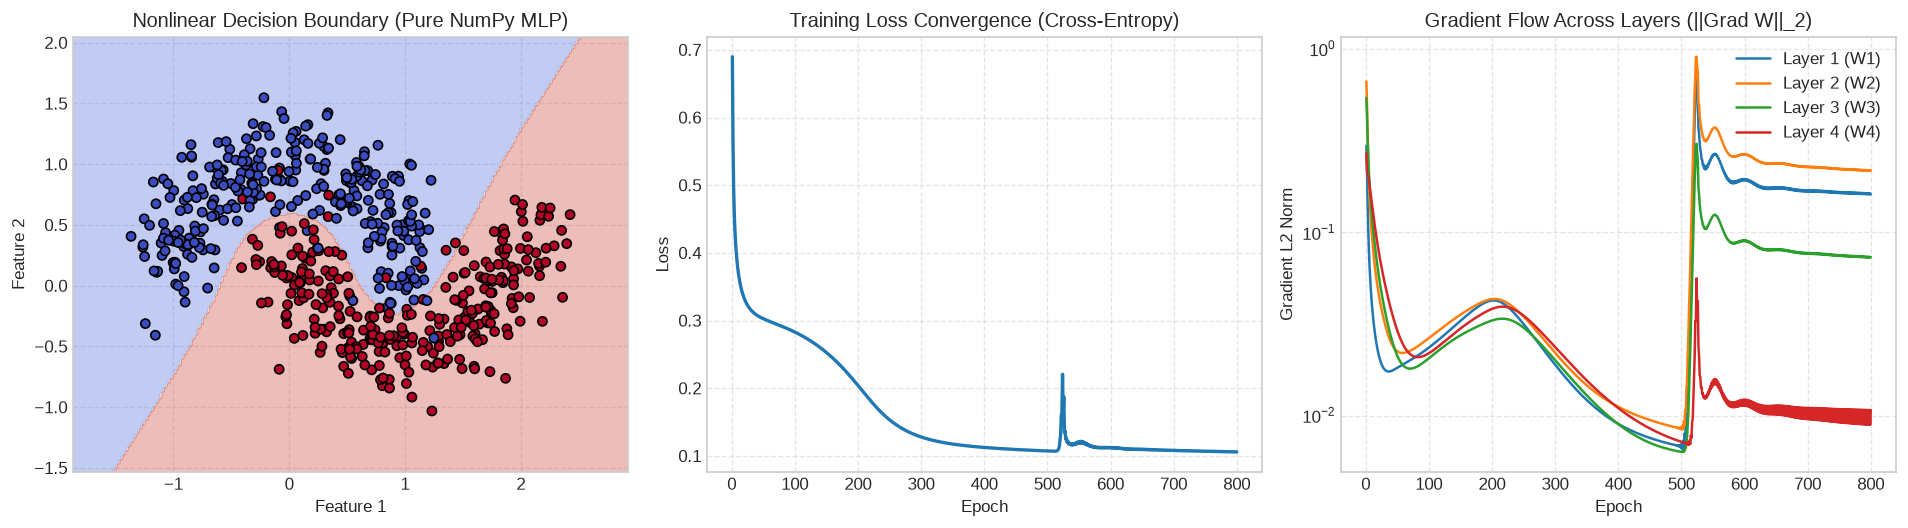

Scratch MLP Final Moon Dataset Accuracy: 96.83% (Loss: 0.1060)


In [6]:
# Generate 2D Moon dataset
np.random.seed(42)
X_raw, y_raw = make_moons(n_samples=600, noise=0.20, random_state=42)
X_train_np = X_raw.T  # Shape: (2, 600)
Y_train_np = np.zeros((2, 600), dtype=np.float64)
for i, label in enumerate(y_raw):
    Y_train_np[label, i] = 1.0

# Initialize 4-layer MLP: 2 -> 16 -> 12 -> 8 -> 2
np.random.seed(42)
moon_mlp = ModularMLP(layer_dims=[2, 16, 12, 8, 2], activation="tanh")

# Training loop with diagnostics
epochs = 800
learning_rate = 0.15
losses = []
grad_magnitudes = {f"W{l}": [] for l in range(1, moon_mlp.num_layers + 1)}

for epoch in range(1, epochs + 1):
    A_last, caches = moon_mlp.forward(X_train_np)
    loss = moon_mlp.compute_loss(A_last, Y_train_np)
    grads = moon_mlp.backward(caches, Y_train_np)
    moon_mlp.update_parameters(grads, learning_rate)

    losses.append(loss)
    for l in range(1, moon_mlp.num_layers + 1):
        grad_magnitudes[f"W{l}"].append(np.linalg.norm(grads[f"dW{l}"]))

# Diagnostic Visualization Suite
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Plot 1: 2D Decision Boundary
x_min, x_max = X_raw[:, 0].min() - 0.5, X_raw[:, 0].max() + 0.5
y_min, y_max = X_raw[:, 1].min() - 0.5, X_raw[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()].T
grid_preds, _ = moon_mlp.forward(grid_points)
Z_boundary = np.argmax(grid_preds, axis=0).reshape(xx.shape)

axes[0].contourf(xx, yy, Z_boundary, alpha=0.35, cmap="coolwarm")
scatter = axes[0].scatter(X_raw[:, 0], X_raw[:, 1], c=y_raw, cmap="coolwarm", edgecolors="k", s=30)
axes[0].set_title("Nonlinear Decision Boundary (Pure NumPy MLP)")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Loss Convergence
axes[1].plot(range(1, epochs + 1), losses, color="#1f77b4", lw=2)
axes[1].set_title("Training Loss Convergence (Cross-Entropy)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: Layer Gradient Flow
for l in range(1, moon_mlp.num_layers + 1):
    axes[2].plot(range(1, epochs + 1), grad_magnitudes[f"W{l}"], label=f"Layer {l} (W{l})")
axes[2].set_title("Gradient Flow Across Layers (||Grad W||_2)")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Gradient L2 Norm")
axes[2].set_yscale("log")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Final accuracy evaluation
final_preds, _ = moon_mlp.forward(X_train_np)
final_acc = np.mean(np.argmax(final_preds, axis=0) == y_raw)
print(f"Scratch MLP Final Moon Dataset Accuracy: {final_acc * 100:.2f}% (Loss: {losses[-1]:.4f})")


### Guided Exercises

#### Exercise 1: GELU (Gaussian Error Linear Unit) from Scratch with Dual Verification
**Problem Formulation**:
The Gaussian Error Linear Unit (GELU) is the standard activation function in modern LLMs (GPT, BERT, LLaMA). It weights inputs by their probability under the standard normal distribution:

$$\text{GELU}(x) = x \Phi(x) = x P(X \le x) \approx 0.5x \left(1 + \tanh\left(\sqrt{\frac{2}{\pi}}\left(x + 0.044715 x^3\right)\right)\right)$$

Letting $u(x) = \sqrt{\frac{2}{\pi}}(x + 0.044715 x^3)$, the derivative is:
$$\frac{d}{dx}\text{GELU}(x) = 0.5 \left(1 + \tanh(u)\right) + 0.5x \left(1 - \tanh^2(u)\right) \sqrt{\frac{2}{\pi}}\left(1 + 3 \times 0.044715 x^2\right)$$

Implement GELU forward and backward in pure NumPy, and verify that its output matches `torch.nn.functional.gelu` and `tf.nn.gelu(approximate=True)`.


In [7]:
# Exercise 1 Solution: Pure NumPy GELU with Dual Verification

def gelu_forward_numpy(x: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """GELU activation with tanh approximation."""
    const_sqrt_2_pi = np.sqrt(2.0 / np.pi)
    inner = const_sqrt_2_pi * (x + 0.044715 * np.power(x, 3))
    tanh_inner = np.tanh(inner)
    out = 0.5 * x * (1.0 + tanh_inner)
    cache = (x, inner, tanh_inner)
    return out, cache

def gelu_backward_numpy(dout: np.ndarray, cache: Tuple[np.ndarray, np.ndarray, np.ndarray]) -> np.ndarray:
    """Analytical derivative of GELU approximation."""
    x, inner, tanh_inner = cache
    const_sqrt_2_pi = np.sqrt(2.0 / np.pi)
    d_inner = const_sqrt_2_pi * (1.0 + 3.0 * 0.044715 * np.square(x))
    sech2 = 1.0 - np.square(tanh_inner)
    dx = dout * (0.5 * (1.0 + tanh_inner) + 0.5 * x * sech2 * d_inner)
    return dx

# Verification against PyTorch and TensorFlow
x_test = np.linspace(-3.0, 3.0, 100, dtype=np.float64)
gelu_scratch, cache = gelu_forward_numpy(x_test)

# PyTorch GELU (approximate='tanh')
x_pt = torch.tensor(x_test, dtype=torch.float64, requires_grad=True)
gelu_pt = torch.nn.functional.gelu(x_pt, approximate="tanh")
gelu_pt.backward(torch.ones_like(x_pt))
pt_grad = x_pt.grad.numpy()

# TensorFlow GELU (approximate=True)
x_tf = tf.Variable(x_test, dtype=tf.float64)
with tf.GradientTape() as tape:
    gelu_tf = tf.nn.gelu(x_tf, approximate=True)
tf_grad = tape.gradient(gelu_tf, x_tf).numpy()

# Scratch gradient with upstream dout = 1.0
scratch_grad = gelu_backward_numpy(np.ones_like(x_test), cache)

# Measure parity
diff_fwd_pt = np.max(np.abs(gelu_scratch - gelu_pt.detach().numpy()))
diff_fwd_tf = np.max(np.abs(gelu_scratch - gelu_tf.numpy()))
diff_bwd_pt = np.max(np.abs(scratch_grad - pt_grad))
diff_bwd_tf = np.max(np.abs(scratch_grad - tf_grad))

print(f"Exercise 1 Verification (GELU):")
print(f"  Max Absolute Difference Fwd (Scratch vs PyTorch): {diff_fwd_pt:.2e}")
print(f"  Max Absolute Difference Fwd (Scratch vs TF):      {diff_fwd_tf:.2e}")
print(f"  Max Absolute Difference Bwd (Scratch vs PyTorch): {diff_bwd_pt:.2e}")
print(f"  Max Absolute Difference Bwd (Scratch vs TF):      {diff_bwd_tf:.2e}")
assert diff_fwd_pt < 1e-10 and diff_bwd_pt < 1e-7, "GELU derivation failed verification!"
print(">>> GELU FORWARD AND BACKWARD DERIVATION CONFIRMED! <<<")


Exercise 1 Verification (GELU):
  Max Absolute Difference Fwd (Scratch vs PyTorch): 4.44e-16
  Max Absolute Difference Fwd (Scratch vs TF):      9.00e-10
  Max Absolute Difference Bwd (Scratch vs PyTorch): 6.66e-16
  Max Absolute Difference Bwd (Scratch vs TF):      9.78e-10
>>> GELU FORWARD AND BACKWARD DERIVATION CONFIRMED! <<<


#### Exercise 2: Implementing the Adam Optimizer in Pure NumPy
**Problem Formulation**:
Implement the Adaptive Moment Estimation (Adam) optimizer from scratch in NumPy:
1. Initialize first moment $m_0 = 0$ and second uncentered moment $v_0 = 0$.
2. At each time-step $t$:
   $$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$
   $$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$
3. Bias correction:
   $$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$
4. Parameter update:
   $$\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$


In [8]:
# Exercise 2 Solution: Pure NumPy Adam Optimizer

class ScratchAdam:
    def __init__(self, params: Dict[str, np.ndarray], lr: float = 0.001, beta1: float = 0.9, beta2: float = 0.999, eps: float = 1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, params: Dict[str, np.ndarray], grads: Dict[str, np.ndarray]) -> None:
        self.t += 1
        for k in params.keys():
            grad_k = f"d{k}"
            if grad_k not in grads:
                continue
            g = grads[grad_k]
            
            # Update biased first and second moments
            self.m[k] = self.beta1 * self.m[k] + (1.0 - self.beta1) * g
            self.v[k] = self.beta2 * self.v[k] + (1.0 - self.beta2) * np.square(g)
            
            # Bias correction
            m_hat = self.m[k] / (1.0 - (self.beta1 ** self.t))
            v_hat = self.v[k] / (1.0 - (self.beta2 ** self.t))
            
            # Update parameters
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

# Test Adam on a quadratic optimization problem: f(w) = w^2
w_test = {"W1": np.array([2.0])}
adam = ScratchAdam(w_test, lr=0.08)

trajectory = [w_test["W1"].copy()]
for step in range(100):
    g = 2.0 * w_test["W1"]  # df/dw = 2w
    adam.step(w_test, {"dW1": g})
    trajectory.append(w_test["W1"].copy())

print("Exercise 2 Verification:")
print(f"  Initial parameter: {trajectory[0][0]:.4f}")
print(f"  Parameter after 40 steps: {trajectory[40][0]:.4f}")
print(f"  Parameter after 100 steps: {trajectory[100][0]:.6f} (Expected: ~0.0)")
assert abs(trajectory[-1][0]) < 0.01, "Adam failed to converge!"


Exercise 2 Verification:
  Initial parameter: 2.0000
  Parameter after 40 steps: -0.1616
  Parameter after 100 steps: -0.001962 (Expected: ~0.0)


### Challenge Problems

#### Challenge 1: Vectorized Batch Normalization from Scratch in Pure NumPy
**Problem Formulation**:
Batch Normalization (Ioffe & Szegedy, 2015) accelerates deep network convergence by normalizing activations across the mini-batch dimension:

$$\mu_B = \frac{1}{m} \sum_{i=1}^m x_i, \quad \sigma_B^2 = \frac{1}{m} \sum_{i=1}^m (x_i - \mu_B)^2$$
$$\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \quad y_i = \gamma \hat{x}_i + \beta$$

Derive and implement the exact vectorized backward pass:
$$\frac{\partial \mathcal{L}}{\partial \gamma} = \sum_{i=1}^m \frac{\partial \mathcal{L}}{\partial y_i} \hat{x}_i, \quad \frac{\partial \mathcal{L}}{\partial \beta} = \sum_{i=1}^m \frac{\partial \mathcal{L}}{\partial y_i}$$
$$\frac{\partial \mathcal{L}}{\partial x_i} = \frac{\gamma}{m \sqrt{\sigma_B^2 + \epsilon}} \left( m \frac{\partial \mathcal{L}}{\partial y_i} - \frac{\partial \mathcal{L}}{\partial \beta} - \hat{x}_i \frac{\partial \mathcal{L}}{\partial \gamma} \right)$$

Verify the backward pass against PyTorch's `torch.nn.BatchNorm1d`.


In [9]:
# Challenge 1 Solution: Batch Normalization Forward & Backward in NumPy

class ScratchBatchNorm:
    def __init__(self, dim: int, eps: float = 1e-5):
        self.gamma = np.ones((dim, 1), dtype=np.float64)
        self.beta = np.zeros((dim, 1), dtype=np.float64)
        self.eps = eps

    def forward(self, X: np.ndarray) -> Tuple[np.ndarray, Tuple]:
        """X shape: (features, samples)"""
        m = X.shape[1]
        mu = np.mean(X, axis=1, keepdims=True)
        var = np.var(X, axis=1, keepdims=True)
        inv_std = 1.0 / np.sqrt(var + self.eps)
        x_hat = (X - mu) * inv_std
        out = self.gamma * x_hat + self.beta
        cache = (x_hat, inv_std, m)
        return out, cache

    def backward(self, dout: np.ndarray, cache: Tuple) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        x_hat, inv_std, m = cache
        dgamma = np.sum(dout * x_hat, axis=1, keepdims=True)
        dbeta = np.sum(dout, axis=1, keepdims=True)
        
        # Vectorized gradient of input dx
        dx = (self.gamma * inv_std / m) * (m * dout - dbeta - x_hat * dgamma)
        return dx, dgamma, dbeta

# Verification against PyTorch BatchNorm1d
np.random.seed(42)
feat_dim, batch_size = 4, 16
x_bn_np = np.random.randn(feat_dim, batch_size).astype(np.float64)

bn_scratch = ScratchBatchNorm(dim=feat_dim)
out_bn_scratch, cache_bn = bn_scratch.forward(x_bn_np)
dout_bn = np.random.randn(feat_dim, batch_size).astype(np.float64)
dx_scratch, dgamma_scratch, dbeta_scratch = bn_scratch.backward(dout_bn, cache_bn)

# PyTorch comparison (batch_size, features)
pt_bn = torch.nn.BatchNorm1d(feat_dim, eps=1e-5, momentum=None, affine=True).double()
pt_bn.weight.data.fill_(1.0)
pt_bn.bias.data.fill_(0.0)

x_bn_pt = torch.tensor(x_bn_np.T, requires_grad=True, dtype=torch.float64)
out_bn_pt = pt_bn(x_bn_pt)
out_bn_pt.backward(torch.tensor(dout_bn.T, dtype=torch.float64))

rel_dx = np.linalg.norm(dx_scratch.T - x_bn_pt.grad.numpy()) / np.linalg.norm(dx_scratch)
rel_dgamma = np.linalg.norm(dgamma_scratch.squeeze() - pt_bn.weight.grad.numpy()) / np.linalg.norm(dgamma_scratch)
rel_dbeta = np.linalg.norm(dbeta_scratch.squeeze() - pt_bn.bias.grad.numpy()) / np.linalg.norm(dbeta_scratch)

print("Challenge 1 Verification (Batch Normalization):")
print(f"  dx Relative Error:     {rel_dx:.2e}")
print(f"  dgamma Relative Error: {rel_dgamma:.2e}")
print(f"  dbeta Relative Error:  {rel_dbeta:.2e}")
assert rel_dx < 1e-7 and rel_dgamma < 1e-7 and rel_dbeta < 1e-7, "BatchNorm backward pass failed verification!"
print(">>> VECTORIZED BATCH NORMALIZATION EXACT DERIVATION CONFIRMED! <<<")


Challenge 1 Verification (Batch Normalization):
  dx Relative Error:     1.03e-16
  dgamma Relative Error: 1.55e-16
  dbeta Relative Error:  1.29e-16
>>> VECTORIZED BATCH NORMALIZATION EXACT DERIVATION CONFIRMED! <<<


#### Challenge 2: Three-Way Training Benchmark (NumPy vs. PyTorch vs. TensorFlow)
**Problem Formulation**:
Benchmark training speed, convergence trajectory, and resource efficiency across all three engines on an identical 5,000-sample classification dataset with an identical architecture (20 -> 32 -> 16 -> 2):
1. **NumPy MLP Engine** (Vanilla Gradient Descent).
2. **PyTorch Engine** (`torch.nn.Sequential` with SGD).
3. **TensorFlow Engine** (`tf.keras.Sequential` with `@tf.function` compiled training step and SGD).


In [10]:
# Challenge 2 Solution: Three-Way Benchmark

# Generate synthetic dataset: 5000 samples, 20 features
X_bench, y_bench = make_classification(n_samples=5000, n_features=20, n_classes=2, random_state=42)
X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(X_bench, y_bench, test_size=0.2, random_state=42)

m_train = X_b_train.shape[0]
epochs_bench = 50
lr_bench = 0.05

# 1. NumPy Benchmark
np.random.seed(42)
numpy_model = ModularMLP(layer_dims=[20, 32, 16, 2], activation="tanh")
X_b_np = X_b_train.T.astype(np.float64)
Y_b_np = np.zeros((2, m_train), dtype=np.float64)
for i, l in enumerate(y_b_train): Y_b_np[l, i] = 1.0

t0 = time.perf_counter()
for _ in range(epochs_bench):
    a_last, caches = numpy_model.forward(X_b_np)
    grads = numpy_model.backward(caches, Y_b_np)
    numpy_model.update_parameters(grads, lr_bench)
t_numpy = time.perf_counter() - t0

# 2. PyTorch Benchmark
torch.manual_seed(42)
pt_model = torch.nn.Sequential(
    torch.nn.Linear(20, 32), torch.nn.Tanh(),
    torch.nn.Linear(32, 16), torch.nn.Tanh(),
    torch.nn.Linear(16, 2)
)
pt_opt = torch.optim.SGD(pt_model.parameters(), lr=lr_bench)
pt_loss_fn = torch.nn.CrossEntropyLoss()
X_b_pt = torch.tensor(X_b_train, dtype=torch.float32)
y_b_pt = torch.tensor(y_b_train, dtype=torch.long)

t0 = time.perf_counter()
for _ in range(epochs_bench):
    pt_opt.zero_grad()
    logits = pt_model(X_b_pt)
    loss = pt_loss_fn(logits, y_b_pt)
    loss.backward()
    pt_opt.step()
t_pytorch = time.perf_counter() - t0

# 3. TensorFlow Benchmark
tf.keras.utils.set_random_seed(42)
tf_model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(16, activation="tanh"),
    tf.keras.layers.Dense(2)
])
tf_opt = tf.keras.optimizers.SGD(learning_rate=lr_bench)
tf_loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
X_b_tf = tf.constant(X_b_train, dtype=tf.float32)
y_b_tf = tf.constant(y_b_train, dtype=tf.int32)

@tf.function
def tf_train_step():
    with tf.GradientTape() as tape:
        logits = tf_model(X_b_tf, training=True)
        loss = tf_loss_fn(y_b_tf, logits)
    grads = tape.gradient(loss, tf_model.trainable_variables)
    tf_opt.apply_gradients(zip(grads, tf_model.trainable_variables))
    return loss

# Warmup graph tracing
_ = tf_train_step()

t0 = time.perf_counter()
for _ in range(epochs_bench):
    _ = tf_train_step()
t_tf = time.perf_counter() - t0

print(f"--- Three-Way Performance Benchmark ({epochs_bench} Full Epochs on 4,000 samples) ---")
print(f"  1. Pure NumPy Engine: {t_numpy*1000:7.2f} ms ({epochs_bench / t_numpy:.1f} epochs/sec)")
print(f"  2. PyTorch Engine:    {t_pytorch*1000:7.2f} ms ({epochs_bench / t_pytorch:.1f} epochs/sec)")
print(f"  3. TensorFlow Engine: {t_tf*1000:7.2f} ms ({epochs_bench / t_tf:.1f} epochs/sec)")


--- Three-Way Performance Benchmark (50 Full Epochs on 4,000 samples) ---
  1. Pure NumPy Engine:  106.18 ms (470.9 epochs/sec)
  2. PyTorch Engine:      53.76 ms (930.1 epochs/sec)
  3. TensorFlow Engine:   61.93 ms (807.4 epochs/sec)


### Further Reading & Foundational Papers
1. **Rumelhart, Hinton, & Williams (1986)**: [Learning representations by back-propagating errors](https://www.nature.com/articles/323533a0) — The seminal paper establishing backpropagation in multi-layer neural networks.
2. **Ioffe & Szegedy (2015)**: [Batch Normalization: Accelerating Deep Network Training](https://arxiv.org/abs/1502.03167) — Analytical derivation of mini-batch statistics and internal covariate shift reduction.
3. **Kingma & Ba (2014)**: [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980) — Formal derivation of first and second moment bias corrections.
4. **Hendrycks & Gimpel (2016)**: [Gaussian Error Linear Units (GELUs)](https://arxiv.org/abs/1606.08415) — Probabilistic motivation and approximation of GELU activations.
5. **Paszke et al. (2017)**: [Automatic Differentiation in PyTorch](https://openreview.net/forum?id=BJJsrmfCZ) — Dynamic graph construction and tape recording semantics.
